In [2]:
import os
import numpy as np
import collections.abc
collections.Iterable = collections.abc.Iterable
collections.Mapping = collections.abc.Mapping
collections.MutableSet = collections.abc.MutableSet
collections.MutableMapping = collections.abc.MutableMapping
import matplotlib
from matplotlib.pylab import *
import matplotlib.pyplot as plt
import matplotlib.colors as col
from astrodendro import Dendrogram, ppv_catalog
from astropy import units as u
from astropy import wcs
from astropy.io import fits
from astropy.table.table import Column
from astropy.table import Table
from astropy.io import ascii
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scimes.scimes.scimes_alt import SpectralCloudstering
import matplotlib.axes as maxes
from scipy.optimize import curve_fit
import time
import copy
import pickle
import h5py
from astropy.wcs import WCS
import pandas as pd

In [2]:
# Run without fear

def hd2d(hd):

	# Create bi-dimensional header
	mhd = fits.PrimaryHDU(np.zeros([hd['NAXIS2'],hd['NAXIS1']])).header

	for i in ['1','2']:
		for t in ['CRVAL','CRPIX','CDELT','CTYPE','CROTA','CUNIT']:
			if hd.get(t+i) != None:
				mhd[t+i] = hd[t+i]

	for t in ['BUNIT','BMAJ','BMIN','BPA','RESTFRQ']:
		if hd.get(t) != None:
			mhd[t] = hd[t]

	return mhd


# Function to generate the integrated intensity map
def mom0map(hdu):

	hd = hdu.header
	data = hdu.data

	# Generate moment 0 map in K km/s
	mom0 = np.nansum(data,axis=0)*abs(hd['CDELT3'])/1000.

	return fits.PrimaryHDU(mom0,hd2d(hd))

def Gaussian(x, mu, sigma, amp=None):
    """
    Returns a Gaussian distribution of given mean, standard deviation and
    (optionally) amplitude. This is used to calculate the rms for non-SNR
    emisssion maps that SCIMES needs

    Arguments:
        x     : float - list or numpy array for the 'x' values
        mu    : float - mean value of the distribution
        sigma : float - standard deviation
        amp   : float - if given, gives the amplitude of the distribution. If 
                not given, the distribution is normalised.

    Returns:
        Gaussian distribution. float.
    """
    term1 = 1 / (sigma * np.sqrt(2 * np.pi))
    term2 = np.exp(-0.5 * ((x - mu) / sigma)**2)
    if amp is None:
        return term1 * term2
    else:
        return amp * term2

In [3]:
# Run without fear

filename = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_SNR'    
#filename = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/orion_12CO'    

CO12, hCO12 = fits.getdata(filename+'.fits', 0, header=True)

CO12_in = CO12.reshape(-1)

CO12_histo, CO12_bins = np.histogram(CO12_in[~np.isnan(CO12_in)], bins=200, range=(-2,7))

In [4]:
# This takes a horribly long time, if it doesn't work go load it from the py version in the next cell

for i in (filename+'.fits', 'temp'): 




    # Make dendrogram



    print('Make dendrogram from the full cube')

    hdu = fits.open(filename+'.fits')[0]
    data = hdu.data
    hd = hdu.header

    if len(data.shape) == 4:
        data = data[0, :, :, :]

   # rms = abs(CO12_popt[1]) Use this if you're running an emission map, or a custom value below!
    rms=0.3 # rms=1 for SNR cubes, 0.3 for orion example
    ppbeam = 1.3 # 14.81 for a 23 arcsec beam with 5.976 arcsec pixel size. 1.3 for orion example
    min_val = 1*rms # 1, 1.5, 2, 2.5, 3 
    min_del = 2*rms # 1, 2, 3, 4, 5
    min_npix=25 # 25 is the custom value, may use multiples of ppbeam like below

    d = Dendrogram.compute(data, min_value=min_val,
                           min_delta=min_del,min_npix=3*ppbeam,
                           verbose=True)

   # delete existing file
   # os.system('rm -rf '+filename+'_dendrogram.fits')
   # create new file
   # d.save_to(filename+'min_del_2_dendrogram.fits')
    print("\n Dendrogram made!")

# Making the catalog
    print("Making a simple catalog of dendrogram structures")
    
    metadata = {}
    metadata['data_unit'] = u.Jy
    w = wcs.WCS(hdu.header)
    metadata['wcs'] = w


    # This should be Kelvin! By being Jy, it does no unit conversion.
    cat = ppv_catalog(d, metadata, fields=['major_sigma',
                                            'minor_sigma',
                                            'area_ellipse',
                                             'radius',
                                             'position_angle',
                                             'v_rms',
                                             'x_cen',
                                             'y_cen',
                                             'v_cen',
                                             'flux',
                                             'area_exact'])

    # Centre position
    xcens = cat['x_cen'].data
    ycens = cat['y_cen'].data
    vcens = cat['v_cen'].data

    # Constants

    delta_arcsec = 5.976        # grid size in arcsec
    delta_velocity = 0.5        # channel size in km/s
        
    s=1 # Radius [arcsecs]

    major_arcsec = delta_arcsec*cat['major_sigma'].data
    minor_arcsec = delta_arcsec*cat['minor_sigma'].data
    rads = delta_arcsec*cat['radius'].data

    # Velocity dispersion [km/s]

    sigvs = delta_velocity*cat['v_rms'].data

    # Luminosity/integrated intensity [K.km/s]

    luminosities = cat['flux'].data*delta_velocity

    # Volume [(arcsec**2)*km/s]

    volumes = cat['area_ellipse'].data*(delta_arcsec**2.)*sigvs

    # Update the catalog

    cat.add_column(Column(name='radius_arcsec', data=rads))
    # , units=u.arcsec))
    cat.add_column(Column(name='sigv_kms', data=sigvs))
    # , units=u.km/u.s))
    cat.add_column(Column(name='luminosity', data=luminosities))
    #  , units=u.K*u.km/u.s))
    cat.add_column(Column(name='volume', data=volumes))
 
    cat.add_column(Column(name='xcens', data=xcens))
    cat.add_column(Column(name='ycens', data=ycens))
    cat.add_column(Column(name='vcens', data=vcens))
    cat.add_column(Column(name='major_arcsec', data=major_arcsec))
    cat.add_column(Column(name='minor_arcsec', data=minor_arcsec))

    print("\n Catalogue made!")


Make dendrogram from the full cube
Generating dendrogram using 238,943 of 5,548,950 pixels (4.306093945701439% of data)

[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                               

/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),
/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),


[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                


[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[=>                                       ] 4%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>                                      ] 5%
[==>        

/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),
/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),


[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                

In [4]:
#d.save_to('dendrogram.hdf5')
d = Dendrogram.load_from('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_dendrogram.fits')

In [5]:
cat = Table.read("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_catalog.fits", format="fits")

- Collecting connectivity information
- Creating affinity matrices
- Start spectral clustering
-- Rescaling volume matrix
-- Estimated scaling parameter: 369259.494210
-- Rescaling luminosity matrix
-- Estimated scaling parameter: 211819.048381
-- Guessed number of clusters = 83
-- Number of k-means iteration: 1


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
/Users/kyriakos.trakakis/COLTE/scimes/scimes/old_spectral_embedding.py:42: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/kyriakos.trakakis/COLTE/scimes/scimes/old_spectral_embedding.py:42: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/kyriakos.trakakis/COLTE/scimes/scimes/old_spectral_embedding.py:42: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/kyriakos.trakakis/COLTE/scimes/scimes/old_spectral_embedding.py:42: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/kyriakos.trakakis/COLTE/scimes/scimes/old_spectral_embedding.py:42: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/kyriakos.trakaki

-- Best cluster number found through SILHOUETTE (0.887395)= 94
Unassignable cluster 5
Unassignable cluster 13
Unassignable cluster 29
Unassignable cluster 32
Unassignable cluster 43
Unassignable cluster 61
Unassignable cluster 65
-- Final cluster number (after cleaning) 88
-- Final clustering configuration silhoutte 0.293711
Generate assignment cubes...

 Clusters ready!

 Leaves ready!
Made dendrogram for cube /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_SNR with parameters min_val= 2.0, min_del= 2.0 and min_npix= 25
Elapsed time: 0.8574194153149922 minutes


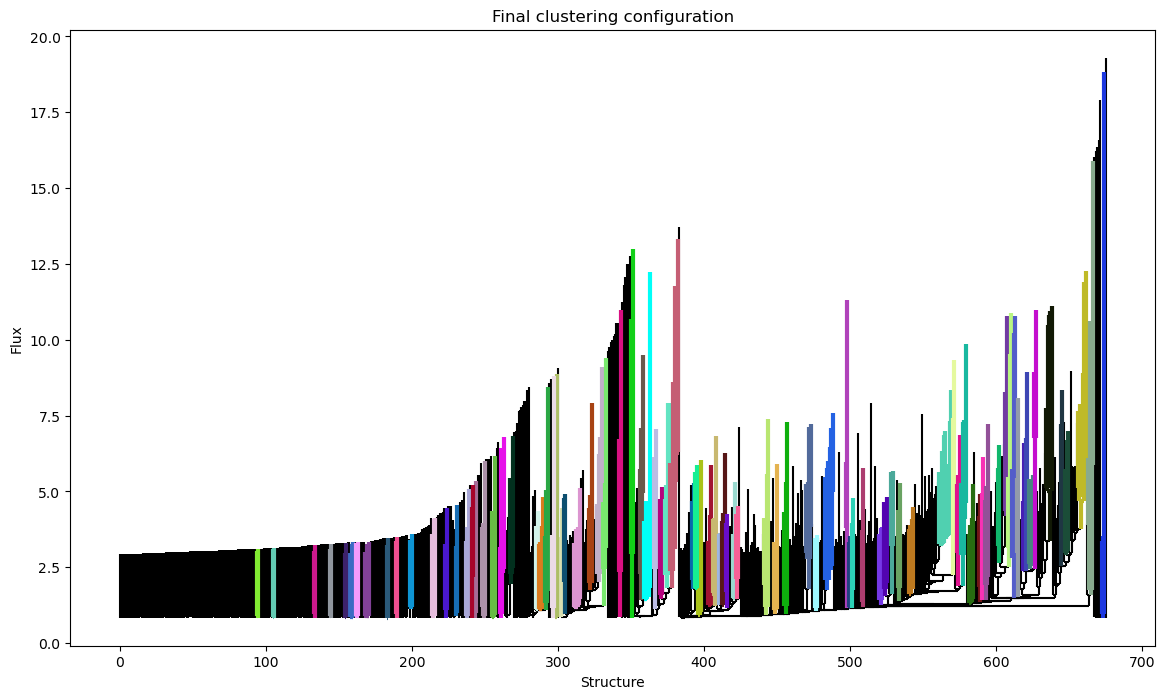

In [7]:
start_time = time.time()
filename = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_SNR' 

hdu = fits.open(filename+'.fits')[0]
data = hdu.data
hd = hdu.header

# rms = abs(CO12_popt[1]) Use this if you're running an emission map, or a custom value below!
rms      = 1 # rms=1 for SNR cubes, 0.3 for orion example
ppbeam   = 14.81 # 14.81 for a 23 arcsec beam with 5.976 arcsec pixel size. 1.3 for orion example
min_val  = 2*rms # 1, 1.5, 2, 2.5, 3 
min_del  = 2*rms # 1, 2, 3, 4, 5
min_npix = 25 # 25 is the custom value, may use multiples of ppbeam like below

delta_arcsec = 5.976        # grid size in arcsec
delta_velocity = 0.5 

# Calling the clustering procedure
# Save_all = False rejects isolated and unclustered leaves, and some leaves from branches
    
gmcs = SpectralCloudstering(d, cat, hd, blind=True, rms=rms, s2nlim=3,
                                save_all=False)
gmcs.colors = ['r', 'g', 'b', 'y', 'c', 'm'] # This somehow helps with the following plot
gmcs.showdendro()
    
   # Filtered catalogues we have used in the past
   # filtered_cat = cat[(cat["structure_type=T"] > 23) & (cat["parent"] == -1)] 
   # filtered_cat = cat[(cat["structure_type"] == "T") | (cat["parent"] == -1)]
#filtered_cat = cat[(cat["v_rms"]>2)&(cat["minor_arcsec"]>69)]
    
    
    #os.system('rm -rf '+filename+'_parentless_apparent_catalog.fits')
    #os.system('rm -rf '+filename+'_clusters.fits')
    #os.system('rm -rf '+filename+'_filtered_clusters.fits')
    #os.system('rm -rf '+filename+'_leaf.fits')
    #os.system('rm -rf '+filename+'_catalog.fits')
    #os.system('rm -rf '+filename+'_catalogue.dat')
    

print("\n Clusters ready!")
    
   # ascii.write(cat, filename+'_catalogue.dat')
    
#cat.write(filename+'_min_del_2_new_savefalse_catalog.fits', overwrite='True')
#gmcs.clusters_asgn.writeto(filename+'_min_del_2_new_savefalse_clusters.fits',overwrite='True')
#gmcs.leaves_asgn.writeto(filename+'min_del_2_new_savefalse_leaves.fits',overwrite='True')
#gmcs.trunks_asgn.writeto(filename+'_min_del_2_new_savefalse_trunks.fits',overwrite='True')
    
   # filtered_cat.write(filename+'_min_del_'+str(min_del/rms)+'_single_parent_catalogue.fits',overwrite='True')
   # gmcs_2.clusters_asgn.writeto(filename+'_min_del_2_new_savefalse_singleparent_structures.fits',overwrite='True')
    
   # gmcs_2.leaves_asgn.data = np.where(np.isin(gmcs_2.leaves_asgn.data, list(filtered_values)), gmcs_2.leaves_asgn.data, -1)
   # gmcs_2.leaves_asgn.writeto(filename+'_filtered_leaf.fits')
    
print("\n Leaves ready!")


# Unite the data of clusters and trunks and create a PrimaryHDU with the copied header
   # clusters_asgn_data = gmcs_2.clusters_asgn.data
   # trunks_asgn_data = gmcs.trunks_asgn.data
   # union_data = np.where(clusters_asgn_data != -1, clusters_asgn_data, trunks_asgn_data)
   # hdu = fits.PrimaryHDU(data=union_data, header=header)

# Save with header
   # hdu.writeto(filename + '_min_del_'+str(min_del/rms)+'_trunks_or_parentless_structures.fits', overwrite=True)


print('Made dendrogram for cube '+filename+ ' with parameters min_val= '+str(min_val/rms)+', min_del= '+str(min_del/rms)+' and min_npix= '+str(min_npix))

end_time = time.time()
elapsed_time = end_time - start_time
print("Elapsed time:", elapsed_time/60, "minutes")

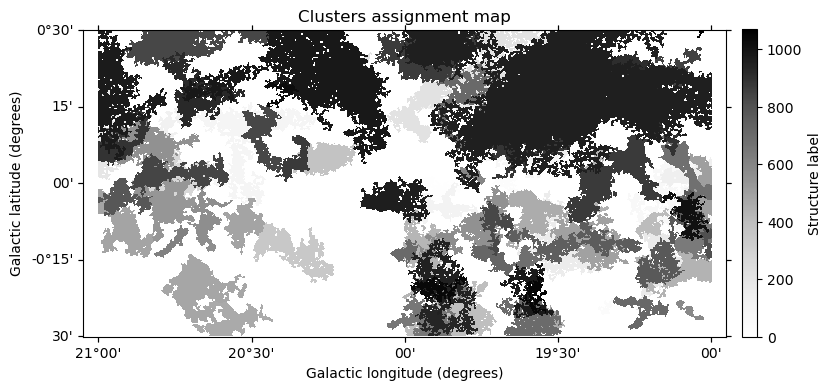

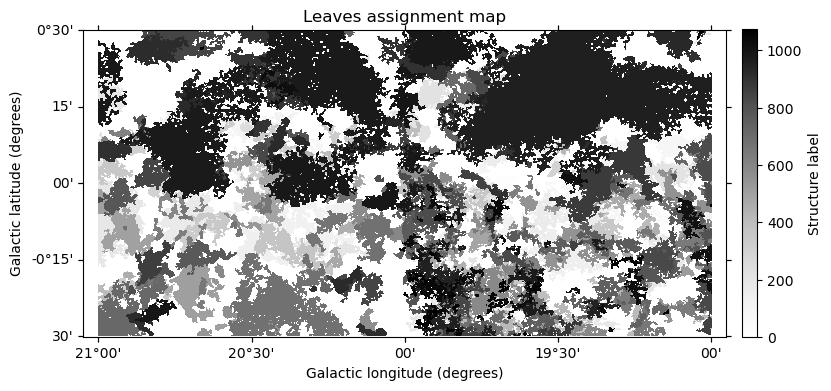

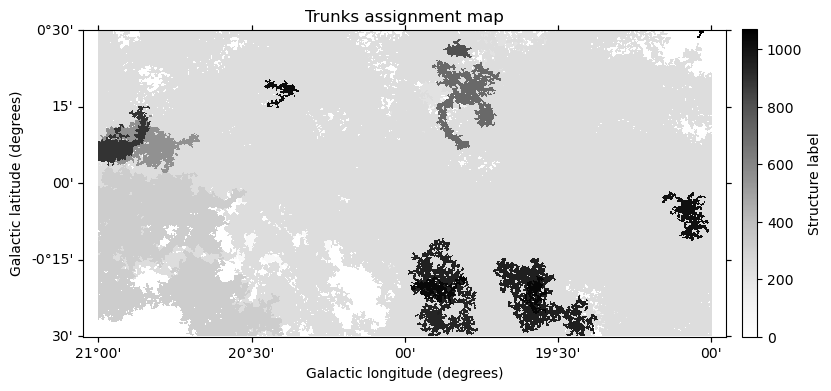

Image the results


In [30]:
# Imaging, run fearlessly
cubes = [gmcs.clusters_asgn,
         gmcs.leaves_asgn,
         gmcs.trunks_asgn]
titles = ['Clusters', 'Leaves', 'Trunks']

for cube, title in zip(cubes, titles):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection=wcs_2d)
    
    im = ax.imshow(np.nanmax(cube.data, axis=0),
                   origin='lower',
                   interpolation='nearest',
                   cmap='Greys')
    
    ax.set_title(title + ' assignment map')
    ax.set_xlabel('Galactic longitude (degrees)')
    ax.set_ylabel('Galactic latitude (degrees)')
    
    # Attach colorbar to the image and axis
    cbar = fig.colorbar(im, ax=ax, shrink=0.5, pad=0.02)  # shrink helps with size alignment
    cbar.set_label('Structure label')

plt.show()
print("Image the results")


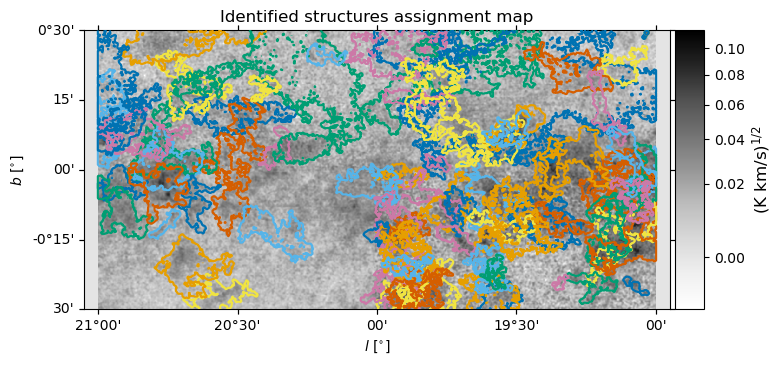

In [45]:
# Just visualisation, run fearlessly

from astropy.visualization import simple_norm

filename = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned' 
hdu = fits.open(filename+'.fits')[0]
data = hdu.data
hd = hdu.header

clusts = gmcs.clusters
colors = gmcs.colors
# Replace gmcs.colors with a colorblind-friendly palette
colors = [
    '#E69F00',  # orange
    '#56B4E9',  # sky blue
    '#009E73',  # green
    '#0072B2',  # blue
    '#D55E00',  # vermillion
    '#CC79A7',   # purple-pink
    '#F0E442',  # yellow
]


# Create integrated intensity map
mhdu = mom0map(hdu)

norm = simple_norm(mhdu.data, 'sqrt')

w = wcs.WCS(mhdu.header)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(1,1,1,projection=w)

im = ax.imshow(mhdu.data,origin='lower',\
	interpolation='nearest',cmap='Greys',norm=norm)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05, axes_class=maxes.Axes)
cbar = fig.colorbar(im, cax=cax, orientation = 'vertical')
cbar.set_label(r'(K km/s)$^{1/2}$', fontsize = 12)

ax.set_title('Identified structures assignment map')
ax.set_xlabel(r'$l$ [$^{\circ}$]')
ax.set_ylabel(r'$b$ [$^{\circ}$]')


count = 0
for c in clusts:
    mask = d[c].get_mask()
    mask_coll = np.nanmax(mask, axis=0)

    ax.contour(mask_coll,
               colors=[colors[count % len(colors)]],  # cycle through colors
               linewidths=1.5,
               levels=[0])

    count += 1
plt.savefig("FGN_020_13CO_23arcsec_SNR_clusters_moment.png", dpi=300, bbox_inches='tight')
plt.show()

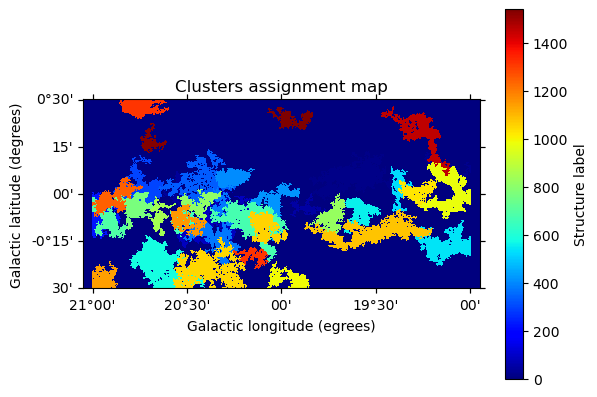

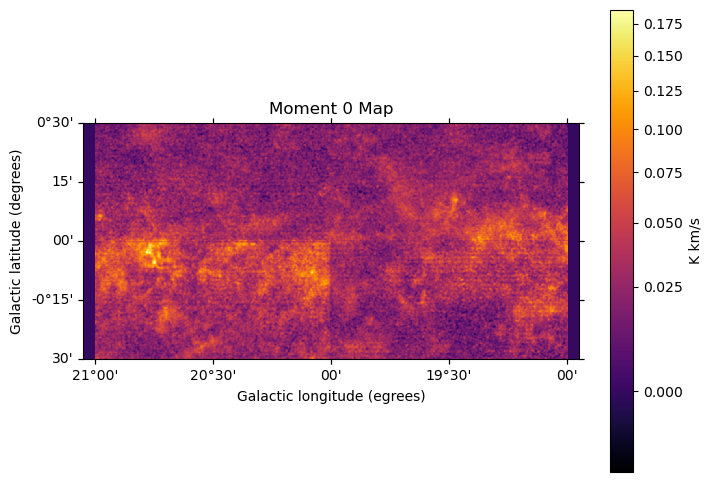

In [70]:
# Clusters fail for some reason, run fearlessly
#cube=fits.getdata("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_042_13CO_23arcsec_aligned_SNR_min_del_2_clusters_new.fits")
cube=fits.getdata("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_020_13CO_23arcsec_aligned_SNR_min_del_2_new_vrms_over3.fits")

fig=plt.figure()
ax = fig.add_subplot(111, projection=wcs_2d)
plt.imshow(np.nanmax(cube.data,axis=0),origin='lower',\
		interpolation='nearest',cmap='jet')
plt.title('Clusters assignment map')
plt.colorbar(label='Structure label')
plt.xlabel("Galactic longitude (egrees)")
plt.ylabel("Galactic latitude (degrees)")
#plt.savefig("FGN_020_13CO_23arcsec_SNR_clusters_assignment_map.png", dpi=300, bbox_inches='tight')

# Plot just the moment map for reference
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(1,1,1,projection=w)

im = ax.imshow(mhdu.data,origin='lower',\
	interpolation='nearest',cmap='inferno',norm=norm)


# Add a colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('K km/s')

# Set labels
ax.set_title("Moment 0 Map")
ax.set_xlabel("Galactic longitude (egrees)")
ax.set_ylabel("Galactic latitude (degrees)")
#plt.savefig("FGN_042_13CO_23arcsec_SNR_moment_map", dpi=300, bbox_inches='tight')

plt.show()

In [45]:
# Defining subsets you want to work with, either to produce new cubes or to overlay on moment maps
# Hello, I am cell above.

clusters_table = Table(gmcs.catalog)
cluster_ids = set(gmcs.clusters)
ids_cat = clusters_table[[row['_idx'] in cluster_ids for row in clusters_table]]

# Sort filtered clusters by a property, e.g., 'radius'
ids_cat.sort('v_rms')
sorted_filtered_cat=ids_cat[(ids_cat['minor_arcsec']>69) & (ids_cat['v_rms']>3)]
sorted_filtered_cats=ids_cat[ids_cat['minor_arcsec']>69]

clusts_good=sorted_filtered_cat['_idx']

In [46]:
sorted_filtered_cat

_idx,area_ellipse,area_exact,flux,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,y_cen,radius_arcsec,sigv_kms,luminosity,volume,xcens,ycens,vcens,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type
,pix2,pix2,Jy,pix,pix,deg,pix,,pix,,,,,,,,,,,,,,,
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,str1
1140,1497.2556970029004,4617.0,66087.73668861389,20.79729465009433,16.530698074323663,-141.85069179415845,18.541677341153797,40172.886465877295,3.0752150789582826,20.94328872796772,-0.4606711213835325,110.80506379073509,1.5376075394791413,33043.868344306946,82217.19420432756,20.94328872796772,-0.4606711213835325,40172.886465877295,124.28463282896371,98.78745169215821,-1,1140,4,T
527,1819.5288244368169,4916.0,50844.730237960815,33.848695686668414,12.342952733584385,89.0464615258498,20.439981676949465,68164.975361377,3.09647593411732,19.37443227109204,0.019484991010157077,122.14933050145,1.54823796705866,25422.365118980408,100604.59820291576,19.37443227109204,0.019484991010157077,68164.975361377,202.27980542353043,73.76148553590028,-1,527,7,T
85,9677.189802233643,19303.0,257283.1434864998,60.493399163225256,36.7318950666302,-160.5781703466321,47.13848947821054,115748.24794259667,3.306644851990646,20.34311211927192,-0.12763463360459992,281.6996131217862,1.653322425995323,128641.5717432499,571383.8925667087,20.34311211927192,-0.12763463360459992,115748.24794259667,361.5085533994341,219.50980491818208,-1,85,17,T
1312,1775.6497312781962,6617.0,120586.5074646473,28.573585718950344,14.269035571145334,176.79282767346126,20.19201602165749,28461.66136828065,3.3201248905746623,20.754744259770735,0.4579784228398733,120.66748774542516,1.6600624452873312,60293.25373232365,105269.5829675303,20.754744259770735,0.4579784228398733,28461.66136828065,170.75574825644725,85.27175657316452,-1,1312,3,T
1314,1467.4863787483453,3417.0,33464.366612911224,25.666562773572487,13.128298133179221,171.6740700883606,18.35642362077698,28810.01047858596,3.363581324878568,20.150099713689805,-0.3293098626294294,109.69798755776323,1.681790662439284,16732.183306455612,88138.81216806277,20.150099713689805,-0.3293098626294294,28810.01047858596,153.3833791348692,78.45470964387903,-1,1314,6,T
408,1371.7734586035008,5210.0,97751.80723881721,26.449610096267843,11.908722786994211,-174.4454738221926,17.74770617461696,70416.49845555425,3.4798151769349506,20.26705618779974,0.07942734851501516,106.06029209951096,1.7399075884674753,48875.90361940861,85237.31397690179,20.26705618779974,0.07942734851501516,70416.49845555425,158.06286993529662,71.16652737507741,345,290,2,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1077,7459.4885272388065,18713.0,311273.9612464905,88.60495730780454,19.330945393884317,-172.20945455237842,41.386200494181885,39655.873706012964,5.469076391305746,19.53224492597003,-0.21323009982972027,247.32393415323094,2.734538195652873,155636.98062324524,728474.278301551,19.53224492597003,-0.21323009982972027,39655.873706012964,529.5032248714399,115.52172967385268,-1,1077,11,T


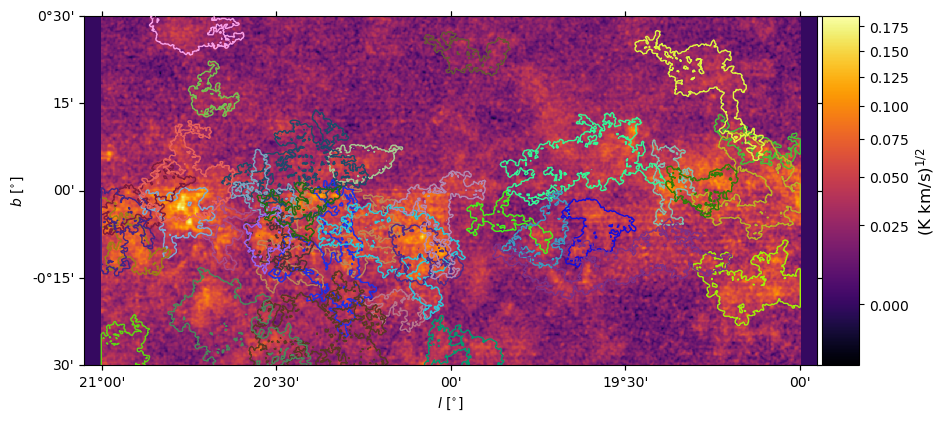

In [48]:
# Overlaying the selected subset of clusters to the moment map. Run fearlessly.

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(1,1,1,projection=w)

im = ax.imshow(mhdu.data,origin='lower',\
	interpolation='nearest',cmap='inferno',norm=norm)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05, axes_class=maxes.Axes)
cbar = fig.colorbar(im, cax=cax, orientation = 'vertical')
cbar.set_label(r'(K km/s)$^{1/2}$', fontsize = 12)

ax.set_xlabel(r'$l$ [$^{\circ}$]')
ax.set_ylabel(r'$b$ [$^{\circ}$]')


count = 0
for c in clusts_good:
	mask = d[c].get_mask()
	mask_coll = np.nanmax(mask,axis=0)

	ax.contour(mask_coll, colors=colors[count], linewidths=1, levels = [0])

	count = count+1


plt.show()

In [61]:
gmcs_2=copy.deepcopy(gmcs)
header = gmcs_2.clusters_asgn.header

In [69]:
# Saving the cluster subsets.
# CHANGE THE NAME!

filtered_cat = cat[(cat["v_rms"]>3)&(cat["minor_arcsec"]>69)]
filtered_values = set(sorted_filtered_cat.columns[0]) # This might be filtered_cat or sorted_filtered_cat
gmcs_2.clusters_asgn.data = np.where(np.isin(gmcs_2.clusters_asgn.data, list(filtered_values)), gmcs_2.clusters_asgn.data, -1)
#filtered_cat.write(filename+'_min_del_'+str(min_del/rms)+'_single_parent_catalogue.fits',overwrite='True')
gmcs_2.clusters_asgn.writeto(filename+'_min_del_new_vrms_over3.fits',overwrite='True')

In [67]:
filtered_values

{12,
 22,
 40,
 52,
 85,
 225,
 298,
 335,
 373,
 408,
 420,
 527,
 537,
 558,
 581,
 655,
 670,
 686,
 767,
 810,
 820,
 842,
 979,
 990,
 1023,
 1047,
 1056,
 1077,
 1140,
 1153,
 1240,
 1312,
 1314,
 1451,
 1531,
 1539}

# Second, related project starts here

In [73]:
# GPT code to create moment maps for a given velocity range. Works well.
# Run fearlessly

def mom0map_vrange(hdu, vmin, vmax):
    hd = hdu.header
    data = hdu.data
    
    # Extract velocity axis parameters
    vref = hd['CRVAL3']  # Reference velocity (in m/s or Hz)
    dv = hd['CDELT3']    # Velocity channel width
    vref_pix = hd['CRPIX3'] - 1  # Reference pixel (zero-based)

    # Convert velocity to km/s if necessary
    if 'CUNIT3' in hd and hd['CUNIT3'] == 'm/s':
        vref /= 1000  # Convert m/s to km/s
        dv /= 1000     # Convert m/s to km/s

    # Compute velocity at each channel
    nchan = data.shape[0]
    velocities = vref + (np.arange(nchan) - vref_pix) * dv

    # Find the indices corresponding to the velocity range
    vmask = (velocities >= vmin) & (velocities <= vmax)
    imin, imax = np.where(vmask)[0][[0, -1]]  # First and last index in range

    # Compute moment 0 map only over the selected velocity range
    mom0 = np.nansum(data[imin:imax+1], axis=0) * abs(dv)

    return fits.PrimaryHDU(mom0, hd2d(hd))

In [23]:
# Making and saving the moment maps with the contours on them. Just the function though, run fearlessly.
# Take into account this will use the clusts_good defined in cell above. Look for cell above.

output_dir = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps"
os.makedirs(output_dir, exist_ok=True)

def generate_moment_maps(hdu, d, clust_good, sorted_filtered_cat):
    """
    Generates moment 0 maps for each cluster in clust_good using v_cen.
    Overlays the cluster mask as a contour and saves the figure.
    """
    # Iterate over each cluster ID
    for count, c in enumerate(clusts_good):
        # Find the v_cen for the cluster
        v_cen = sorted_filtered_cat[sorted_filtered_cat['_idx'] == c]['v_cen'].item()/1000
        v_rms = sorted_filtered_cat[sorted_filtered_cat['_idx'] == c]['v_rms'].item()

        # Find nearest multiples of 10
        #vmin = (v_cen // 10) * 10  # Round down to nearest 10
        #vmax = vmin + 10  # Round up to next multiple of 10
        #print(vmin, vmax)

        #vmin = round(v_cen - 5)
        #vmax = round(v_cen + 5)
        #print(vmin,vmax)

        vmin = round(v_cen - v_rms - 2)
        vmax = round(v_cen + v_rms + 2)
        print(vmin, vmax)

        # Generate moment 0 map
        mom0_hdu = mom0map_vrange(hdu, vmin, vmax)
        mom0_data = mom0_hdu.data

        # Get cluster mask
        mask = d[c].get_mask()
        mask_coll = np.nanmax(mask, axis=0)

        # Plot the moment map
        fig, ax = plt.subplots(figsize=(6, 5))
        norm = simple_norm(mom0_data, 'sqrt')
        img = ax.imshow(mom0_data, origin='lower', cmap='inferno', norm=norm)
        plt.colorbar(img, ax=ax, label='K km/s')

        # Overlay contour
        ax.contour(mask_coll, colors='cyan', linewidths=0.5, levels=[0])

        # Title and save
        ax.set_title(f"FGN_037_047_cluster {c} ({vmin} to {vmax} km/s)")
        save_path = os.path.join(output_dir, f"FGN_037_047_cluster_{c}.png")
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close(fig)  # Close to free memory

        print(f"Saved: {save_path}")

In [24]:
# Run this to make and save the maps.
generate_moment_maps(hdu, d, clusts_good, sorted_filtered_cat)

16 24
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_10768.png
73 81
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_1847.png
81 89
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_758.png
70 78
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_2053.png
27 35
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_9619.png
65 73
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_2679.png
64 72
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_3057.png
33 41
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_9097.png
11 20
Saved: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Moment maps/FGN_037_047_cluster_11386.png
28 36
Saved: /Users/kyriakos.trakaki

In [74]:
sorted_filtered_cat

_idx,area_ellipse,area_exact,flux,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,y_cen,radius_arcsec,sigv_kms,luminosity,volume,xcens,ycens,vcens,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type
,pix2,pix2,Jy,pix,pix,deg,pix,,pix,,,,,,,,,,,,,,,
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,str1
1140,1497.2556970029004,4617.0,66087.73668861389,20.79729465009433,16.530698074323663,-141.85069179415845,18.541677341153797,40172.886465877295,3.0752150789582826,20.94328872796772,-0.4606711213835325,110.80506379073509,1.5376075394791413,33043.868344306946,82217.19420432756,20.94328872796772,-0.4606711213835325,40172.886465877295,124.28463282896371,98.78745169215821,-1,1140,4,T
527,1819.5288244368169,4916.0,50844.730237960815,33.848695686668414,12.342952733584385,89.0464615258498,20.439981676949465,68164.975361377,3.09647593411732,19.37443227109204,0.019484991010157077,122.14933050145,1.54823796705866,25422.365118980408,100604.59820291576,19.37443227109204,0.019484991010157077,68164.975361377,202.27980542353043,73.76148553590028,-1,527,7,T
85,9677.189802233643,19303.0,257283.1434864998,60.493399163225256,36.7318950666302,-160.5781703466321,47.13848947821054,115748.24794259667,3.306644851990646,20.34311211927192,-0.12763463360459992,281.6996131217862,1.653322425995323,128641.5717432499,571383.8925667087,20.34311211927192,-0.12763463360459992,115748.24794259667,361.5085533994341,219.50980491818208,-1,85,17,T
1312,1775.6497312781962,6617.0,120586.5074646473,28.573585718950344,14.269035571145334,176.79282767346126,20.19201602165749,28461.66136828065,3.3201248905746623,20.754744259770735,0.4579784228398733,120.66748774542516,1.6600624452873312,60293.25373232365,105269.5829675303,20.754744259770735,0.4579784228398733,28461.66136828065,170.75574825644725,85.27175657316452,-1,1312,3,T
1314,1467.4863787483453,3417.0,33464.366612911224,25.666562773572487,13.128298133179221,171.6740700883606,18.35642362077698,28810.01047858596,3.363581324878568,20.150099713689805,-0.3293098626294294,109.69798755776323,1.681790662439284,16732.183306455612,88138.81216806277,20.150099713689805,-0.3293098626294294,28810.01047858596,153.3833791348692,78.45470964387903,-1,1314,6,T
408,1371.7734586035008,5210.0,97751.80723881721,26.449610096267843,11.908722786994211,-174.4454738221926,17.74770617461696,70416.49845555425,3.4798151769349506,20.26705618779974,0.07942734851501516,106.06029209951096,1.7399075884674753,48875.90361940861,85237.31397690179,20.26705618779974,0.07942734851501516,70416.49845555425,158.06286993529662,71.16652737507741,345,290,2,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1077,7459.4885272388065,18713.0,311273.9612464905,88.60495730780454,19.330945393884317,-172.20945455237842,41.386200494181885,39655.873706012964,5.469076391305746,19.53224492597003,-0.21323009982972027,247.32393415323094,2.734538195652873,155636.98062324524,728474.278301551,19.53224492597003,-0.21323009982972027,39655.873706012964,529.5032248714399,115.52172967385268,-1,1077,11,T


In [83]:
# ChatGPT function to find the lowest longitude pixel in a cube that is not NaN or 0.
# Run without fear
# I need to think about this a bit more, tie it into the next code. 

def find_lowest_valid_longitude_pixel(fits_file):
    with fits.open(fits_file) as hdul:
        data = hdul[0].data  # Assuming the first HDU contains the cube
        header = hdul[0].header


    # Identify pixels that are not NaN and greater than 0
    valid_mask = (~np.isnan(data)) & (data > 0)
    valid_pixels = np.argwhere(valid_mask)
    
    if valid_pixels.size == 0:
        print("No valid pixels (non-NaN and > 0) found in the data.")
        return None

    # Extract longitude index (first axis)
    lon_indices = valid_pixels[:, 0]
    min_lon_index = np.min(lon_indices)

    # Find first valid pixel at this longitude
    valid_at_min_lon = valid_pixels[lon_indices == min_lon_index]
    lat_index, vel_index = valid_at_min_lon[0, 1], valid_at_min_lon[0, 2]

    # Convert indices to real-world coordinates using CRPIX and CDELT
    crpix1, cdelt1 = header["CRPIX1"], header["CDELT1"]
    crpix2, cdelt2 = header["CRPIX2"], header["CDELT2"]
    crpix3, cdelt3 = header["CRPIX3"], header["CDELT3"]

    min_longitude = (min_lon_index + 1 - crpix1) * cdelt1
    latitude = (lat_index + 1 - crpix2) * cdelt2
    velocity = (vel_index + 1 - crpix3) * cdelt3

    # Get the actual pixel value
    pixel_value = data[min_lon_index, lat_index, vel_index]

    print("FITS data shape:", data.shape)
    print(f"Lowest Longitude Pixel: Index = {min_lon_index}, Longitude = {min_longitude:.5f}")
    print(f"Corresponding Latitude: Index = {lat_index}, Latitude = {latitude:.5f}")
    print(f"Corresponding Velocity: Index = {vel_index}, Velocity = {velocity:.5f}")
    print(f"Checking indices: Lon={min_lon_index}, Lat={lat_index}, Vel={vel_index}")
    print(f"Corresponding pixel value: {data[min_lon_index, lat_index, vel_index]}")

    print(f"Pixel Value: {pixel_value:.5f}")

    return min_longitude, latitude, velocity#, pixel_value

fits_file='/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_042_13CO_23arcsec_aligned_SNR_min_del_2_clusters_new.fits'
result = find_lowest_valid_longitude_pixel(fits_file)

if result:
    lon, lat, vel = result
    print(f"First valid pixel is at Longitude: {lon:.4f}, Latitude: {lat:.5f}, Velocity: {vel:.4f}")
else:
    print("No valid pixels found in the cube.")


FITS data shape: (385, 601, 1261)
Lowest Longitude Pixel: Index = 125, Longitude = 0.84155
Corresponding Latitude: Index = 180, Latitude = -0.19978
Corresponding Velocity: Index = 1206, Velocity = -200279.50000
Checking indices: Lon=125, Lat=180, Vel=1206
Corresponding pixel value: 34
Pixel Value: 34.00000
First valid pixel is at Longitude: 0.8416, Latitude: -0.19978, Velocity: -200279.5000


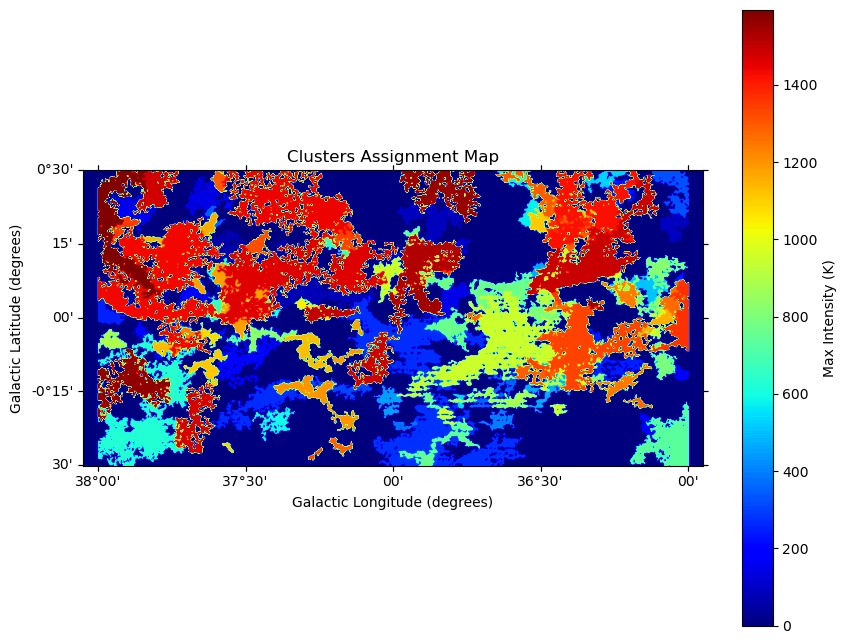

In [66]:
# This is just the cluster assignment but with coordinates, maybe implement this to cluster assignment codes above and delete this.
# Run fearlessly

# Load FITS file
fits_file = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_clusters.fits"  # Replace with your filename
with fits.open(fits_file) as hdul:
    data = hdul[0].data  # Data cube (3D: Velocity, Latitude, Longitude)
    header = hdul[0].header  # Header

# Convert header to 2D projection
header_2d = header.copy()
wcs = WCS(header)  # WCS for full cube
wcs_2d = wcs.dropaxis(2)  # Drop velocity axis

# Compute maximum projection along velocity axis (axis 0)
moment0_map = np.nanmax(data, axis=0)

# Plot with WCS projection
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection=wcs_2d)

im = ax.imshow(moment0_map, origin='lower', cmap='jet')

# Colorbar & Labels
plt.colorbar(im, ax=ax, label="Max Intensity (K)")
ax.set_xlabel("Galactic Longitude (degrees)")
ax.set_ylabel("Galactic Latitude (degrees)")
ax.set_title("Clusters Assignment Map")

# Save the plot (optional)
#plt.savefig("moment0_map.png", dpi=300, bbox_inches="tight")

plt.show()


In [89]:
# First attempt to mask clusters within a set distance of a given longitude.
# This will be helpful for finding clusters on the 10-degree seams.
# Saves output

def mask_clusters_by_longitude_range(fits_file, target_longitude=37, longitude_range=0.1):
    """
    This function will mask the clusters that are within a given range of longitudes
    from the target longitude.

    Parameters:
    fits_file (str): The path to the FITS file.
    target_longitude (float): The central longitude to check for clusters (default is 42).
    longitude_range (float): The longitude range to check around the target (default is 1 degree).

    Returns:
    str: Path to the saved masked FITS file.
    """

    # Load the FITS file
    with fits.open(fits_file) as hdul:
        data = hdul[0].data
        header = hdul[0].header

    # Get WCS information
    w = WCS(header)
    
    # Get longitude values from the header (assume axis 2 is longitude)
    lon_values = w.wcs_pix2world(np.arange(data.shape[2]), 0, 0, 0)[0]  # Longitude values

    # Find indices that are within the longitude range
    valid_lon_indices = np.abs(lon_values - target_longitude) <= longitude_range

    # Find clusters present in the valid longitude range (excluding 0 for background)
    clusters_in_range = np.unique(data[:, :, valid_lon_indices])
    clusters_in_range = clusters_in_range[clusters_in_range > 0]  # Exclude background (0)

    # Create a new mask where only the identified clusters are set to their original values
    masked_cube = np.isin(data, clusters_in_range) * data  # Keeps original cluster values, background 0

    # Generate output filename
    output_filename = os.path.splitext(fits_file)[0] + "_border_masked.fits"

    # Save masked cube as a new FITS file
    hdu = fits.PrimaryHDU(masked_cube, header=header)
 #   hdu.writeto(output_filename, overwrite=True)

    print(f"Masked cube saved as: {output_filename}")

    for cluster in clusters_in_range:
        # Get indices of all voxels belonging to this cluster
        cluster_indices = np.argwhere(data == cluster)

        # Extract their longitude values
        longitudes = lon_values[cluster_indices[:, 2]]  # Longitude axis is assumed to be axis=2

        # Find the index of the voxel with the lowest longitude
        min_lon_idx = np.argmin(longitudes)
        max_lon_idx = np.argmax(longitudes)
        voxel_position_min = cluster_indices[min_lon_idx]  # Get the voxel index (z, y, x)
        voxel_position_max = cluster_indices[max_lon_idx]

        # Convert voxel index to world coordinates
        world_coords_min = w.wcs_pix2world(voxel_position_min[::-1].reshape(1, -1), 0)[0]
        world_coords_max = w.wcs_pix2world(voxel_position_max[::-1].reshape(1, -1), 0)[0]


        # Print results
        print(f"Cluster {cluster}: Lowest Longitude Voxel at {world_coords_min} (lon, lat, velocity)")
        print(f"Cluster {cluster}: Highest Longitude Voxel at {world_coords_max} (lon, lat, velocity)")

    return output_filename



mask_clusters_by_longitude_range("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters.fits")


Masked cube saved as: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters_border_masked.fits
Cluster 75: Lowest Longitude Voxel at [3.70603700e+01 7.28199202e-02 9.06087681e+04] (lon, lat, velocity)
Cluster 75: Highest Longitude Voxel at [3.73836976e+01 1.12817325e-01 9.01087681e+04] (lon, lat, velocity)
Cluster 90: Lowest Longitude Voxel at [3.67437050e+01 3.57811761e-01 8.31087681e+04] (lon, lat, velocity)
Cluster 90: Highest Longitude Voxel at [3.70470367e+01 2.16152233e-01 9.11087681e+04] (lon, lat, velocity)
Cluster 144: Lowest Longitude Voxel at [3.67370385e+01 8.44857148e-02 8.51087681e+04] (lon, lat, velocity)
Cluster 144: Highest Longitude Voxel at [3.69003701e+01 9.48665221e-03 8.81087681e+04] (lon, lat, velocity)
Cluster 153: Lowest Longitude Voxel at [3.68537037e+01 1.22819410e-01 8.81087681e+04] (lon, lat, velocity)
Cluster 153: Highest Longitude Voxel at [3.70020367e+01 7.78199518e-02 8.96087681e+04] (lon, lat, vel

'/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters_border_masked.fits'

In [9]:
# Same thing as above but uses clusters that touch the border, no range
# Saves output

#l_target = 50
#l_start = l_target - 10
l_start = 30
l_target = 40
FGN_path = '/Users/kyriakos.trakakis/Downloads/FUGIN_data/13CO/'

def mask_clusters_by_longitude(fits_file, target_longitude=l_target):
    # Load the FITS file
    with fits.open(fits_file) as hdul:
        data = hdul[0].data
        header = hdul[0].header

    list = []
    list_2 = []

    # Get WCS information
    w = WCS(header)
    
    # Get longitude indices
    lon_indices = np.arange(data.shape[2])  # Assuming (lat, vel, lon) order
    lon_values = w.wcs_pix2world(lon_indices, 0, 0, 0)[0]  # Convert pixel to world coordinates

    # Find index closest to the target longitude
    lon_index = np.abs(lon_values - target_longitude).argmin()
    lon_index_2 = np.abs(lon_values - target_longitude + 10).argmin()

    # Find unique clusters present at the target longitude (excluding 0)
    clusters_at_lon = np.unique(data[:, :, lon_index])
    clusters_at_lon = clusters_at_lon[clusters_at_lon > 0]  # Exclude background (0)

    clusters_at_lon_2 = np.unique(data[:, :, lon_index_2])
    clusters_at_lon_2 = clusters_at_lon_2[clusters_at_lon_2 > 0]  # Exclude background (0)

    # Create a new mask where only those clusters are set to 1
    masked_cube   = np.isin(data, clusters_at_lon) * data  # Keeps original cluster values, background 0
    masked_cube_2 = np.isin(data, clusters_at_lon_2) * data

    for cluster in clusters_at_lon:
        # Get indices of all voxels belonging to this cluster
        cluster_indices = np.argwhere(data == cluster)

        # Extract their longitude values
        longitudes = lon_values[cluster_indices[:, 2]]  # Longitude axis is assumed to be axis=2

        # Find the index of the voxel with the lowest longitude
        min_lon_idx = np.argmin(longitudes)
        max_lon_idx = np.argmax(longitudes)
        voxel_position_min = cluster_indices[min_lon_idx]  # Get the voxel index (z, y, x)
        voxel_position_max = cluster_indices[max_lon_idx]

        # Convert voxel index to world coordinates
        world_coords_min = w.wcs_pix2world(voxel_position_min[::-1].reshape(1, -1), 0)[0]
        world_coords_max = w.wcs_pix2world(voxel_position_max[::-1].reshape(1, -1), 0)[0]


        # Print results
        print(f"Cluster {cluster}: Lowest Longitude Voxel at {world_coords_min} (lon, lat, velocity)")
        print(f"Cluster {cluster}: Highest Longitude Voxel at {world_coords_max} (lon, lat, velocity)")

        list.append(cluster)


    print("\n\n")
    
    for cluster in clusters_at_lon_2:
        # Get indices of all voxels belonging to this cluster
        cluster_indices = np.argwhere(data == cluster)

        # Extract their longitude values
        longitudes = lon_values[cluster_indices[:, 2]]  # Longitude axis is assumed to be axis=2

        # Find the index of the voxel with the lowest longitude
        min_lon_idx = np.argmin(longitudes)
        max_lon_idx = np.argmax(longitudes)
        voxel_position_min = cluster_indices[min_lon_idx]  # Get the voxel index (z, y, x)
        voxel_position_max = cluster_indices[max_lon_idx]

        # Convert voxel index to world coordinates
        world_coords_min = w.wcs_pix2world(voxel_position_min[::-1].reshape(1, -1), 0)[0]
        world_coords_max = w.wcs_pix2world(voxel_position_max[::-1].reshape(1, -1), 0)[0]


        # Print results
        print(f"Cluster {cluster}: Lowest Longitude Voxel at {world_coords_min} (lon, lat, velocity)")
        print(f"Cluster {cluster}: Highest Longitude Voxel at {world_coords_max} (lon, lat, velocity)")

        list_2.append(cluster)

    # Save masked cube as a new FITS file
    hdu = fits.PrimaryHDU(masked_cube, header=header)
  #  hdu.writeto(output_filename, overwrite=True)

    # Generate output filename
    output_filename = os.path.splitext(fits_file)[0] + "_border_masked.fits"

    print(f"Masked cube saved as: {output_filename}")

    return output_filename, list, list_2

output, list, list_2 = mask_clusters_by_longitude(FGN_path + f"FGN_13CO_{l_start}_{l_target}_23arcsec_SNR_spline_min_del_2_parallel_clusters.fits")

clusters_list = f"FGN_13CO_{l_start}_{l_target}_vrms_3_X_factor_masses_spline.csv"
table         = pd.read_csv(FGN_path + clusters_list)

for i in range(len(list)):
    if list[i] in table['_idx'].values:
        print(str(list[i]) + " high l")

for i in range(len(list_2)):
    if list_2[i] in table['_idx'].values:
        print(str(list_2[i]) + " low l")

Changed DATE-OBS from '31/12/49' to '1949-12-31''. [astropy.wcs.wcs]


Cluster 849: Lowest Longitude Voxel at [ 3.84208175e+01 -9.52708333e-01  1.21249248e+04] (lon, lat, velocity)
Cluster 849: Highest Longitude Voxel at [ 3.99999979e+01 -6.74097222e-01  1.14749248e+04] (lon, lat, velocity)
Cluster 1436: Lowest Longitude Voxel at [ 3.99357834e+01 -3.41180556e-01  2.12249248e+04] (lon, lat, velocity)
Cluster 1436: Highest Longitude Voxel at [ 3.99995945e+01 -4.00208333e-01  2.38249248e+04] (lon, lat, velocity)
Cluster 1637: Lowest Longitude Voxel at [ 3.99435529e+01 -7.87430556e-01  2.70749248e+04] (lon, lat, velocity)
Cluster 1637: Highest Longitude Voxel at [ 3.99999935e+01 -6.71736111e-01  2.83749248e+04] (lon, lat, velocity)
Cluster 1701: Lowest Longitude Voxel at [3.97729198e+01 3.97847222e-01 2.83749248e+04] (lon, lat, velocity)
Cluster 1701: Highest Longitude Voxel at [3.99996323e+01 4.33263889e-01 3.03249248e+04] (lon, lat, velocity)
Cluster 3521: Lowest Longitude Voxel at [ 3.87928923e+01 -1.94791667e-01  6.73749248e+04] (lon, lat, velocity)
Clust

In [22]:
# Takes a cube and a list of valid values, masks only the voxels whose values are on the list.
# Extension of the codes above, to mask the clusters on the borders between 10 degree cubes.
# Saves output

def filter_fits_voxels(input_fits, output_fits, valid_values):
    """
    Reads a 3D FITS file, modifies voxel values based on valid_values, and saves the result.
    
    Parameters:
        input_fits (str): Path to the input FITS file.
        output_fits (str): Path to save the modified FITS file.
        valid_values (list of int): List of voxel values to keep (set to 1), others set to 0.
    """
    # Load FITS file
    with fits.open(input_fits) as hdul:
        header = hdul[0].header  # Keep the header
        data = hdul[0].data      # Get the 3D data cube
        
        # Convert data to integer type for comparison
        data = data.astype(int)
        
        # Create a mask where valid values are 1, others 0
        mask = np.isin(data, valid_values).astype(int)
        mask=mask*data
        
        # Save modified data into a new FITS file
        hdu = fits.PrimaryHDU(mask, header=header)
        hdu.writeto(output_fits, overwrite=True)
        
    print(f"Filtered FITS file saved as: {output_fits}")

# Example usage
input_fits = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters.fits"
output_fits = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters_border_values.fits"
valid_values = [90,269, 451, 963, 1523]  # Example list of allowed values
filter_fits_voxels(input_fits, output_fits, valid_values)


Filtered FITS file saved as: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_new_clusters_border_binary.fits


In [23]:
hd

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    3 / number of data axes                            
NAXIS1  =                 5715 / length of data axis 1                          
NAXIS2  =                  608 / length of data axis 2                          
NAXIS3  =                  427 / length of data axis 3                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
LBOUND1 =                -5083 / Pixel origin along axis 1                      
LBOUND2 =                 -302 / Pixel origin along axis 2                      
LBOUND3 =                 -191 / Pixel origin along axis 3                      
OBJECT  = 'Galactic Plane'  

In [63]:
filtered_cat = cat[(cat["sigv_kms"]> 3 / 2.354)&(cat["minor_sigma"] > 69 / 2.354 / 6)]
filtered_values = set(filtered_cat.columns[0]) # This might be filtered_cat or sorted_filtered_cat
gmcs_2.clusters_asgn.data = np.where(np.isin(gmcs_2.clusters_asgn.data, list(filtered_values)), gmcs_2.clusters_asgn.data, -1)
#filtered_cat.write(filename+'_min_del_'+str(min_del/rms)+'_single_parent_catalogue.fits',overwrite='True')
gmcs_2.clusters_asgn.writeto(filename+'_min_del_new_vrms_over3.fits',overwrite='True')

In [65]:
gmcs.trunks_asgn.writeto(filename+'_min_del_2_new_savefalse_trunks.fits',overwrite='True')

In [37]:
l_target = 270
l_end = l_target+10
Mopra_path = '/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/'
clusters_list = f"G{l_start}-{l_target}_13CO_X-factor_masses.csv"
table         = pd.read_csv(Mopra_path + clusters_list)

In [78]:
table['_idx']

0     1333
1     2227
2     2207
3     2016
4      793
5     2395
6     2279
7     1610
8     2113
9     1400
10     730
11    2619
12    1625
13     679
Name: _idx, dtype: int64

In [60]:
list

[9, 65, 293, 305]

In [61]:
clusters_list

'G290-300_13CO_X-factor_masses.csv'

In [69]:
for i in range(len(list_2)):
    print(list_2[i])
    if list_2[i] in table['_idx']:
        print(list_2[i])

1610


In [83]:
9 in table['_idx'].values

False

In [79]:
for i in range(len(table['_idx'])):
    print(table['_idx'][i])

1333
2227
2207
2016
793
2395
2279
1610
2113
1400
730
2619
1625
679


In [82]:
1610 in table['_idx'].values

True